## EDA 노트북입니다

In [1]:
# 모듈 임포트 셀
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
plt.rcParams["font.family"] = "AppleGothic" # 한글 깨짐 방지
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("../outputs", exist_ok=True)

MIN_GROUP = 100   # 그룹별 비율을 볼 때 필요한 최소 기업 수
CLIP = 0.02       # 그래프 그릴 때 잘라낼 상하위 비율

In [3]:
# 데이터 불러오기
df = pd.read_csv("../data/clean.csv", encoding="utf-8-sig")
print(df.shape)
df["성장여부"].value_counts(normalize=True).round(3)

(13389, 64)


성장여부
0    0.673
1    0.327
Name: proportion, dtype: float64

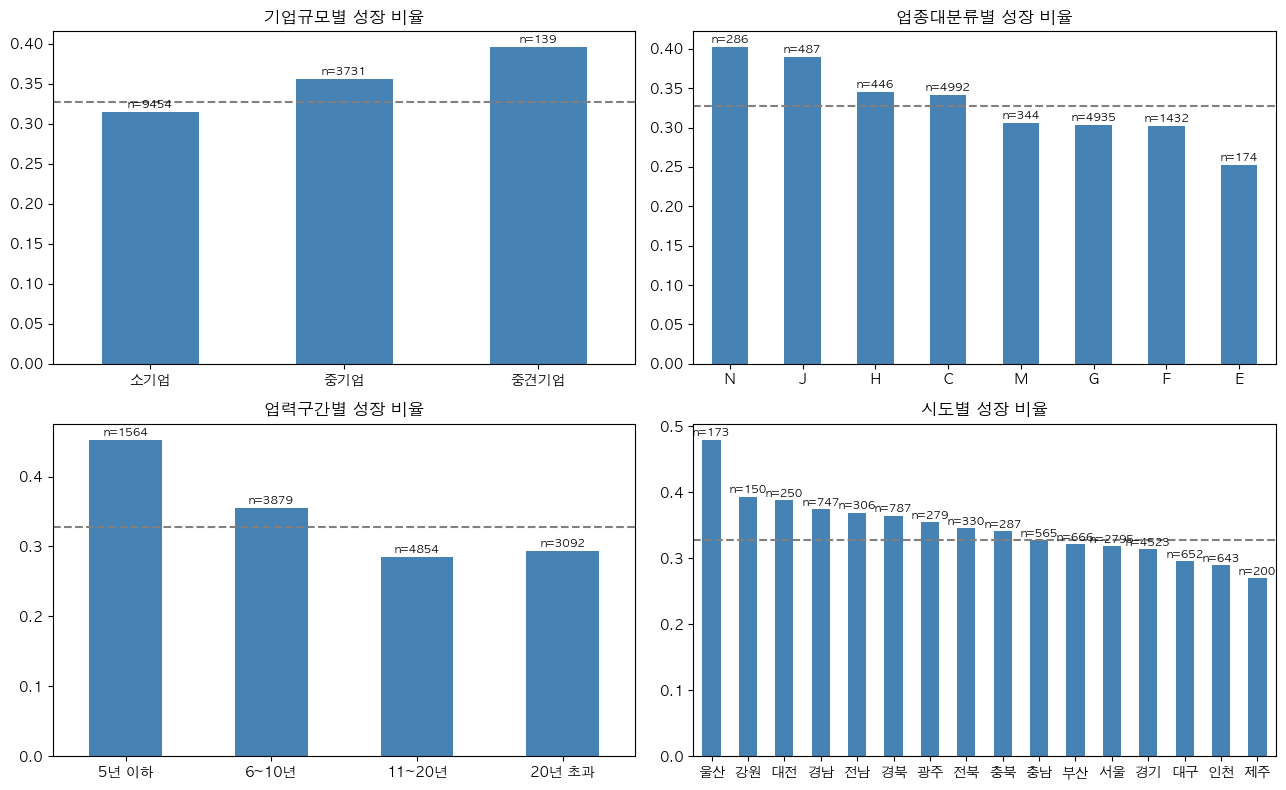

In [4]:
# 규모, 업종, 업력, 지역별 성장 비율
# csv로 읽으면 순서가 사라져서 다시 지정
df["기업규모"] = pd.Categorical(df["기업규모"], categories=["소기업", "중기업", "중견기업", "대기업", "한시성중소기업"])
order = df.groupby("업력구간")["업력"].min().sort_values().index   # 업력 작은 구간부터
df["업력구간"] = pd.Categorical(df["업력구간"], categories=order)

groups = ["기업규모", "업종대분류", "업력구간", "시도"]
ordered = ["기업규모", "업력구간"]   # 순서가 있는 그룹은 비율순으로 정렬하지 않음

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i in range(4):
    ax = axes.flat[i]
    g = groups[i]
    stat = df.groupby(g, observed=True)["성장여부"].agg(["mean", "size"])
    stat = stat[stat["size"] >= MIN_GROUP]
    if g not in ordered:
        stat = stat.sort_values("mean", ascending=False)
    stat["mean"].plot.bar(ax=ax, color="steelblue", rot=0)
    for j in range(len(stat)):
        ax.text(j, stat["mean"].iloc[j] + 0.005, "n=" + str(stat["size"].iloc[j]), ha="center", fontsize=8)
    ax.axhline(df["성장여부"].mean(), color="gray", linestyle="--")   # 전체 평균
    ax.set_title(g + "별 성장 비율")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../outputs/eda_growth_rate_by_group.png")
plt.show()

In [5]:
# 성장 여부별 주요 지표 중앙값
cols = ["업력", "24년 총자산", "24년 매출액", "24년 총자산회전율", "24년 부가가치율", "24년 차입금회전율", "24년 부채비율",
        "22년 총자산", "22년 총자산회전율", "22년 부가가치율", "22년 차입금회전율", "22년 부채비율",
        "자산성장률_22_24", "매출성장률_22_24"]
table = df.groupby("성장여부")[cols].median().T.rename(columns={0: "부", 1: "여"})
table["여-부"] = table["여"] - table["부"]
table.round(2)

성장여부,부,여,여-부
업력,13.00,11.00,-2.00
24년 총자산,45.00,55.00,10.00
24년 매출액,35.10,30.60,-4.50
24년 총자산회전율,0.77,0.59,-0.18
24년 부가가치율,19.30,19.00,-0.30
24년 차입금회전율,3.24,4.36,1.12
24년 부채비율,1.21,1.57,0.36
22년 총자산,35.00,35.00,0.00
22년 총자산회전율,0.61,0.66,0.05
22년 부가가치율,17.20,19.80,2.60


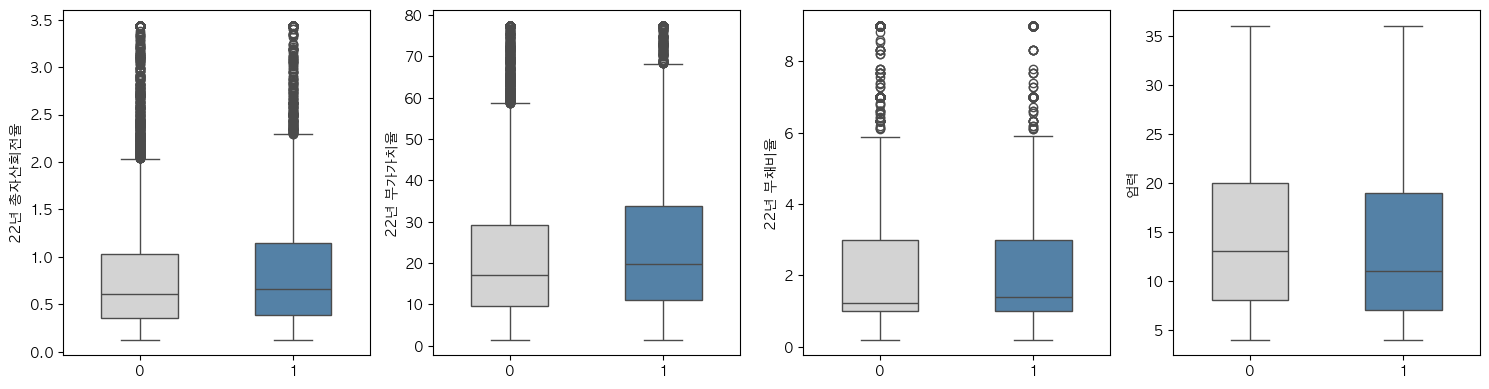

In [6]:
# 분포 비교 (상하위 CLIP 비율은 잘라서 그림)
cols = ["22년 총자산회전율", "22년 부가가치율", "22년 부채비율", "업력"]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for i in range(4):
    col = cols[i]
    data = df[[col, "성장여부"]].dropna().copy()
    data[col] = data[col].clip(data[col].quantile(CLIP), data[col].quantile(1 - CLIP))
    sns.boxplot(data=data, x="성장여부", y=col, hue="성장여부", palette=["lightgray", "steelblue"], width=0.5, legend=False, ax=axes[i])
    axes[i].set_xlabel("")
plt.tight_layout()
plt.savefig("../outputs/eda_boxplot.png")
plt.show()

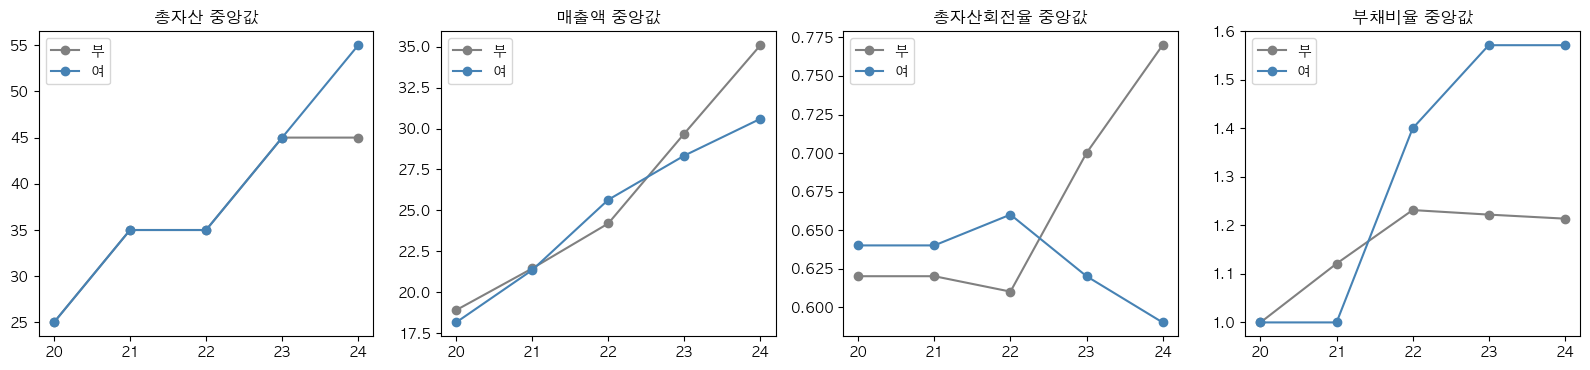

In [7]:
# 20년부터 24년까지 두 그룹의 중앙값 추세
years = ["20", "21", "22", "23", "24"]
items = ["총자산", "매출액", "총자산회전율", "부채비율"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for i in range(4):
    cols = [y + "년 " + items[i] for y in years]
    for label in [0, 1]:
        part = df[df["성장여부"] == label]
        color = "steelblue" if label == 1 else "gray"
        name = "여" if label == 1 else "부"
        axes[i].plot(years, part[cols].median().values, marker="o", color=color, label=name)
    axes[i].set_title(items[i] + " 중앙값")
    axes[i].legend()
plt.tight_layout()
plt.savefig("../outputs/eda_trend.png")
plt.show()

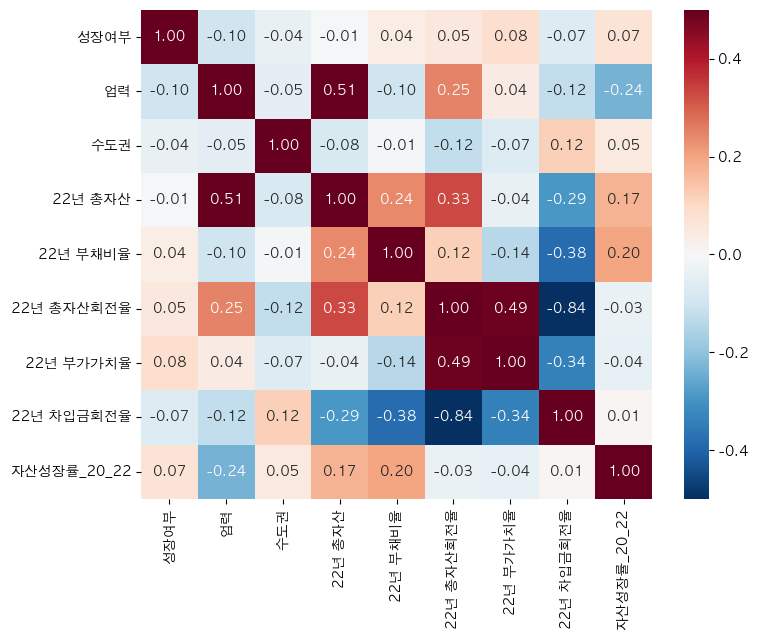

In [8]:
# 지표 간 상관관계 (스피어만)

corr_cols = ["성장여부", "업력", "수도권", "22년 총자산", "22년 부채비율", "22년 총자산회전율",
             "22년 부가가치율", "22년 차입금회전율", "자산성장률_20_22"]
corr = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5)
plt.tight_layout()
plt.savefig("../outputs/eda_corr.png")
plt.show()

In [9]:
# 세부 업종별 성장 비율. 기업 수 MIN_GROUP 이상만
rate = df.groupby("업종명")["성장여부"].agg(["mean", "size"])
rate = rate[rate["size"] >= MIN_GROUP].sort_values("mean", ascending=False)
rate.round(3)

,mean,size
업종명,,
응용 소프트웨어 개발 및 공급업,0.497,155
그 외 자동차용 신품 부품 제조업,0.457,247
육류 포장육 및 냉동육 가공업 (가금류 제외),0.451,133
의약품 도매업,0.437,199
기타 가공식품 도매업,0.403,196
전자상거래 소매업,0.372,269
배관 및 냉ㆍ난방 공사업,0.345,119
"신선, 냉동 및 기타 수산물 도매업",0.331,160
"컴퓨터 및 주변장치, 소프트웨어 도매업",0.304,135


In [10]:
# 같은 업종 안에서 성장 여부별 지표 중앙값. 제조업(C), 도소매업(G)
cols = ["업력", "22년 총자산", "22년 총자산회전율", "22년 부가가치율", "22년 부채비율", "자산성장률_20_22"]
for code in ["C", "G"]:
    part = df[df["업종대분류"] == code]
    print(code, len(part))
    display(part.groupby("성장여부")[cols].median().round(2))

C 4992


,업력,22년 총자산,22년 총자산회전율,22년 부가가치율,22년 부채비율,자산성장률_20_22
성장여부,,,,,,
0,14.0,55.0,0.87,21.40,1.67,0.13
1,12.0,65.0,0.94,23.25,1.91,0.21


G 4935


,업력,22년 총자산,22년 총자산회전율,22년 부가가치율,22년 부채비율,자산성장률_20_22
성장여부,,,,,,
0,12.0,35.0,0.44,10.0,1.22,0.13
1,9.0,25.0,0.44,11.2,1.00,0.29


In [11]:
# 자본잠식, 상장 여부와 성장
print(df.groupby("22년 자본잠식")["성장여부"].agg(["mean", "size"]).round(3))
print()
print(df.groupby("상장등록법인")["성장여부"].agg(["mean", "size"]).round(3))

           mean   size
22년 자본잠식              
0         0.327  13197
1         0.370    192

          mean   size
상장등록법인               
W        0.385     65
기타       0.324  11752
등록법인     0.143     21
상장기업     0.316     19
외감법인     0.353   1466
코넥스상장기업  0.000      7
코스닥상장기업  0.390     59


In [12]:
# 여, 부 그룹 차이 검정. 범주형은 카이제곱, 연속형은 Mann-Whitney
# 기업 수가 많아 p값은 거의 다 유의하므로 효과크기(Cramer V, 순위 상관)로 크기를 본다
rows = []
for g in ["기업규모", "업종대분류", "업력구간", "수도권", "시도"]:
    table = pd.crosstab(df[g], df["성장여부"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"변수": g, "검정": "카이제곱", "p값": p, "효과크기": v})

num_test = ["업력", "22년 총자산", "22년 총자산회전율", "22년 부가가치율", "22년 차입금회전율", "22년 부채비율",
            "매출성장률_20_22", "자산성장률_20_22"]
for c in num_test:
    a = df.loc[df["성장여부"] == 1, c].dropna()
    b = df.loc[df["성장여부"] == 0, c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    r = 2 * u / (len(a) * len(b)) - 1   # 순위 상관. 양수면 여 그룹이 큼
    rows.append({"변수": c, "검정": "Mann-Whitney", "p값": p, "효과크기": r})

tests = pd.DataFrame(rows)
tests["p값"] = tests["p값"].map(lambda x: "{:.1e}".format(x))
tests.round(3)

,변수,검정,p값,효과크기
0,기업규모,카이제곱,2.1e-05,0.045
1,업종대분류,카이제곱,9.7e-13,0.084
2,업력구간,카이제곱,8.2e-39,0.116
3,수도권,카이제곱,2.9e-05,0.036
4,시도,카이제곱,1.3e-06,0.066
5,업력,Mann-Whitney,3.0e-30,-0.121
6,22년 총자산,Mann-Whitney,4.3e-01,-0.008
7,22년 총자산회전율,Mann-Whitney,3.8e-10,0.067
8,22년 부가가치율,Mann-Whitney,3.1e-22,0.103
9,22년 차입금회전율,Mann-Whitney,2.3e-14,-0.083


지속가능      0      1
성장여부              
0     0.269  0.404
1     0.203  0.124

유형
성장 지속가능    0.124
성장 위험      0.203
정체 안정      0.404
정체 위험      0.269
Name: proportion, dtype: float64


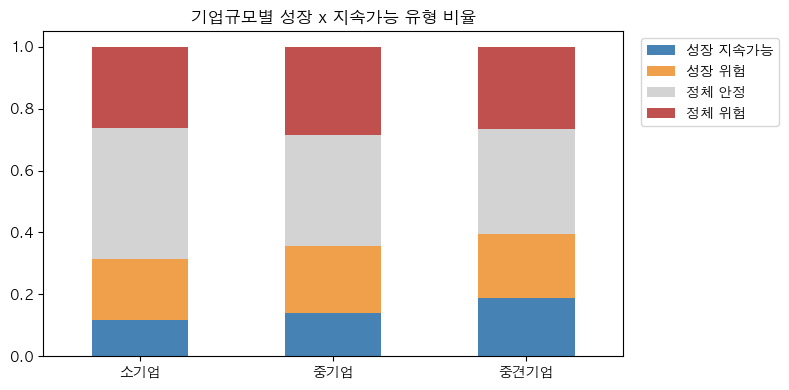

유형,성장 지속가능,성장 위험,정체 안정,정체 위험
기업규모,,,,
소기업,0.116,0.198,0.424,0.262
중기업,0.141,0.215,0.358,0.287
중견기업,0.187,0.209,0.338,0.266


In [13]:
# 성장여부 x 지속가능 2x2. 성장하지만 건전성 조건을 못 채우는 기업이 얼마나 되는지
df["유형"] = np.where(df["성장여부"] == 1,
                    np.where(df["지속가능"] == 1, "성장 지속가능", "성장 위험"),
                    np.where(df["지속가능"] == 1, "정체 안정", "정체 위험"))
type_order = ["성장 지속가능", "성장 위험", "정체 안정", "정체 위험"]
print(pd.crosstab(df["성장여부"], df["지속가능"], normalize="all").round(3))
print()
print(df["유형"].value_counts(normalize=True).reindex(type_order).round(3))

share = pd.crosstab(df["기업규모"], df["유형"], normalize="index")[type_order]
share = share[df["기업규모"].value_counts().reindex(share.index) >= MIN_GROUP]
share.plot.bar(stacked=True, figsize=(8, 4), rot=0, color=["steelblue", "#f0a04b", "lightgray", "#c0504d"])
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("기업규모별 성장 x 지속가능 유형 비율")
plt.xlabel("")
plt.tight_layout()
plt.savefig("../outputs/eda_growth_sustain.png")
plt.show()
share.round(3)

In [14]:
# 성장 위험 기업은 무엇이 다른가. 부채비율과 회전율 변화
cols = ["22년 부채비율", "24년 부채비율", "부채비율_변화_22_24", "22년 총자산회전율", "24년 총자산회전율", "회전율_변화_22_24", "자산성장률_22_24"]
df.groupby("유형")[cols].median().reindex(type_order).round(2)

,22년 부채비율,24년 부채비율,부채비율_변화_22_24,22년 총자산회전율,24년 총자산회전율,회전율_변화_22_24,자산성장률_22_24
유형,,,,,,,
성장 지속가능,1.0,1.00,0.0,0.55,0.58,0.00,0.29
성장 위험,2.2,2.43,0.0,0.76,0.60,-0.15,0.21
정체 안정,1.0,1.00,0.0,0.58,0.76,0.13,0.00
정체 위험,3.0,3.00,0.0,0.66,0.80,0.10,0.00
